# What is Multivariate Analysis?
- Multivariate analysis is a statistical technique used to analyze three or more variables at the same time.

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [20]:
df=pd.read_csv('/Users/nidagallusandeep/Downloads/day37_multivariate_analysis(1).csv')

In [21]:
df.head()

,Order_ID,City,Category,Marketing_Channel,Customer_Age,Quantity,Unit_Price_INR,Discount_Percent,Customer_Rating,Revenue_INR,Profit_Margin_Percent,Profit_INR
0,ORD001,Kurnool,Grocery,Online,41,5,6700,15,4.3,28475.0,32,9112.00
1,ORD002,Kurnool,Electronics,Social Media,46,4,7891,15,2.4,26829.4,25,6707.35
2,ORD003,Hyderabad,Electronics,Online,44,3,17367,0,3.3,52101.0,17,8857.17
3,ORD004,Kurnool,Clothing,Store,52,4,2585,5,4.2,9823.0,26,2553.98
4,ORD005,Hyderabad,Electronics,Store,60,5,8719,20,2.5,34876.0,26,9067.76


In [22]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 60 entries, 0 to 59
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Order_ID               60 non-null     object 
 1   City                   60 non-null     object 
 2   Category               60 non-null     object 
 3   Marketing_Channel      60 non-null     object 
 4   Customer_Age           60 non-null     int64  
 5   Quantity               60 non-null     int64  
 6   Unit_Price_INR         60 non-null     int64  
 7   Discount_Percent       60 non-null     int64  
 8   Customer_Rating        60 non-null     float64
 9   Revenue_INR            60 non-null     float64
 10  Profit_Margin_Percent  60 non-null     int64  
 11  Profit_INR             60 non-null     float64
dtypes: float64(3), int64(5), object(4)
memory usage: 5.8+ KB


In [23]:
df.shape

(60, 12)

In [24]:
df.columns

Index(['Order_ID', 'City', 'Category', 'Marketing_Channel', 'Customer_Age',
       'Quantity', 'Unit_Price_INR', 'Discount_Percent', 'Customer_Rating',
       'Revenue_INR', 'Profit_Margin_Percent', 'Profit_INR'],
      dtype='object')

In [25]:
df.duplicated().sum()

np.int64(0)

In [26]:
df.isnull().sum()

Order_ID                 0
City                     0
Category                 0
Marketing_Channel        0
Customer_Age             0
Quantity                 0
Unit_Price_INR           0
Discount_Percent         0
Customer_Rating          0
Revenue_INR              0
Profit_Margin_Percent    0
Profit_INR               0
dtype: int64

In [27]:
df.describe()

,Customer_Age,Quantity,Unit_Price_INR,Discount_Percent,Customer_Rating,Revenue_INR,Profit_Margin_Percent,Profit_INR
count,60.000000,60.000000,60.000000,60.000000,60.000000,60.000000,60.000000,60.000000
mean,40.383333,3.316667,10039.533333,12.333333,3.565000,28056.708333,19.483333,5150.095833
std,10.808176,1.620752,4972.806950,8.206378,0.831544,19475.950284,8.975469,3794.430914
min,21.000000,1.000000,716.000000,0.000000,2.100000,1933.200000,5.000000,408.880000
25%,31.750000,2.000000,6477.500000,5.000000,2.800000,11233.000000,11.750000,2363.835000
50%,39.000000,3.000000,9486.500000,12.500000,3.650000,24931.750000,19.500000,4457.600000
75%,47.500000,5.000000,13755.500000,20.000000,4.300000,42739.075000,26.250000,7908.577500
max,60.000000,6.000000,17932.000000,25.000000,4.900000,79074.000000,34.000000,13750.720000


In [28]:
df.groupby(["City", "Category"])["Revenue_INR"].sum()

City       Category   
Bengaluru  Clothing        64463.35
           Electronics     14852.05
           Furniture       11330.40
           Grocery        118301.60
Chennai    Clothing       137649.30
           Electronics    261906.30
           Furniture       99132.15
           Grocery         26601.90
Hyderabad  Clothing        32785.00
           Electronics    103090.60
           Furniture      200529.60
           Grocery         43272.75
Kurnool    Clothing        96241.00
           Electronics    283936.20
           Furniture      144618.20
           Grocery         44692.10
Name: Revenue_INR, dtype: float64

In [29]:
df.groupby(["City", "Category"]).agg(
    Average_Revenue=("Revenue_INR", "mean"),
    Total_Profit=("Profit_INR", "sum"))
df.head()

,Order_ID,City,Category,Marketing_Channel,Customer_Age,Quantity,Unit_Price_INR,Discount_Percent,Customer_Rating,Revenue_INR,Profit_Margin_Percent,Profit_INR
0,ORD001,Kurnool,Grocery,Online,41,5,6700,15,4.3,28475.0,32,9112.00
1,ORD002,Kurnool,Electronics,Social Media,46,4,7891,15,2.4,26829.4,25,6707.35
2,ORD003,Hyderabad,Electronics,Online,44,3,17367,0,3.3,52101.0,17,8857.17
3,ORD004,Kurnool,Clothing,Store,52,4,2585,5,4.2,9823.0,26,2553.98
4,ORD005,Hyderabad,Electronics,Store,60,5,8719,20,2.5,34876.0,26,9067.76


In [30]:
df.groupby(["Marketing_Channel", "Category"])["Revenue_INR"].mean()

Marketing_Channel  Category   
Online             Clothing       24499.387500
                   Electronics    23352.950000
                   Furniture      15079.242857
                   Grocery        20694.640000
Social Media       Clothing       35487.000000
                   Electronics    37731.080000
                   Furniture      41636.366667
                   Grocery        31166.116667
Store              Clothing       20270.887500
                   Electronics    38171.795000
                   Furniture      32163.792857
                   Grocery        17948.400000
Name: Revenue_INR, dtype: float64

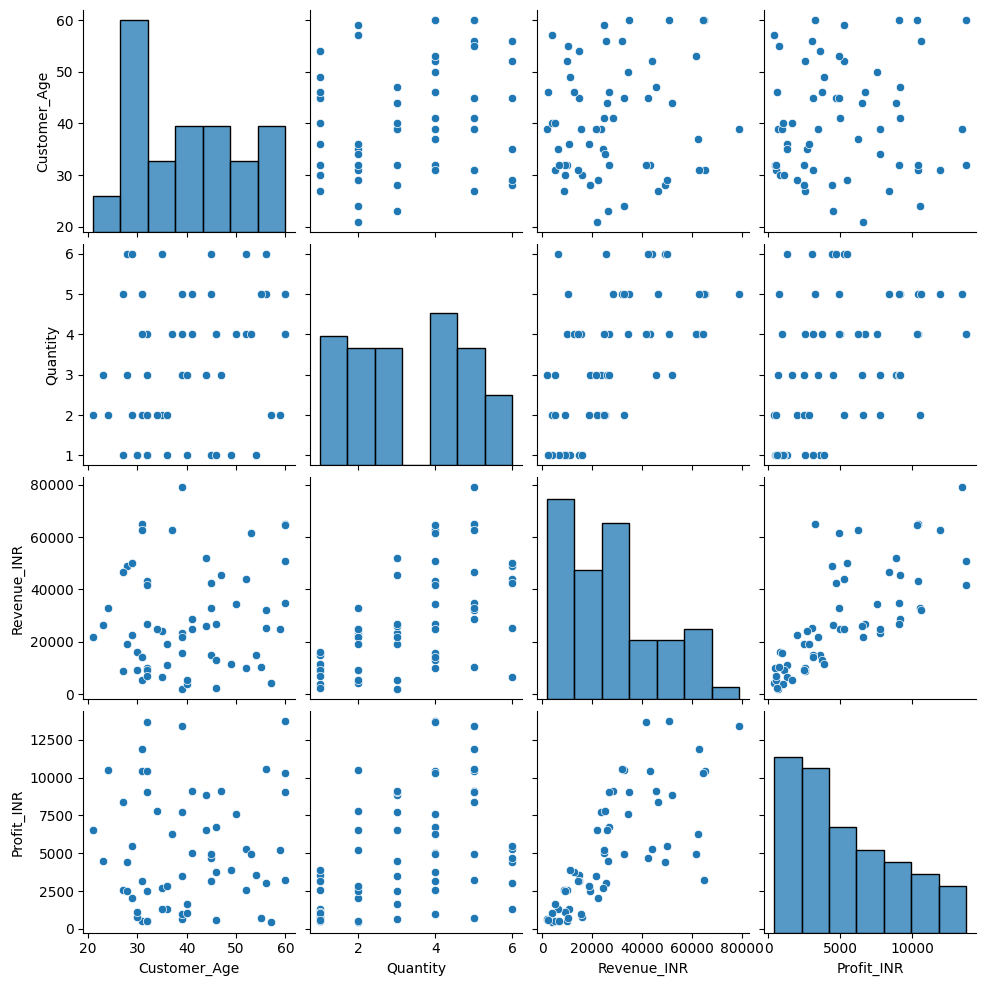

In [31]:
sns.pairplot(df[["Customer_Age", "Quantity", "Revenue_INR", "Profit_INR"]])
plt.show()

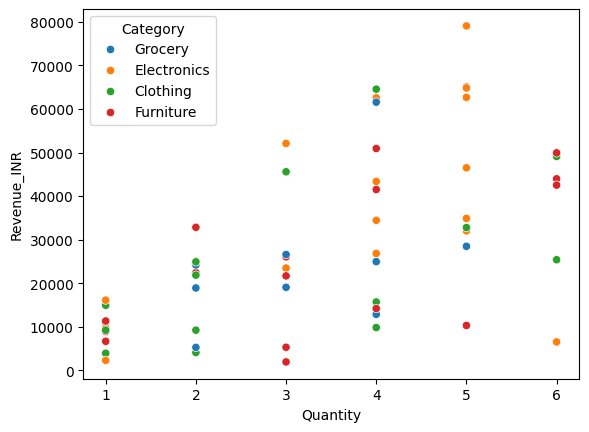

In [33]:
sns.scatterplot(
    data=df,
    x="Quantity",
    y="Revenue_INR",
    hue="Category")
plt.show()

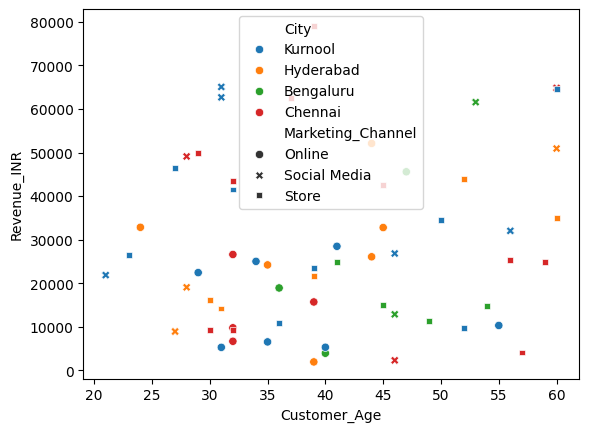

In [34]:
sns.scatterplot(
    data=df,
    x="Customer_Age",
    y="Revenue_INR",
    hue="City",
    style="Marketing_Channel"
)
plt.show()

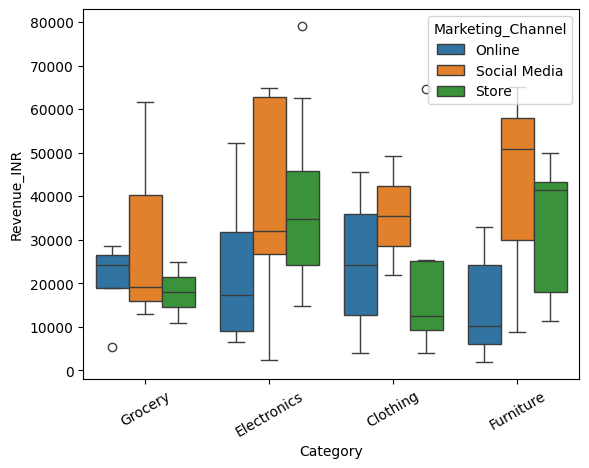

In [35]:
sns.boxplot(
    data=df,
    x="Category",
    y="Revenue_INR",
    hue="Marketing_Channel")
plt.xticks(rotation=30)
plt.show()

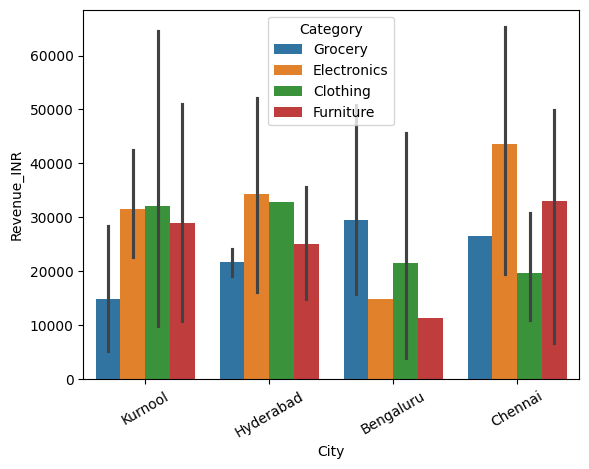

In [36]:
sns.barplot(
    data=df,
    x="City",
    y="Revenue_INR",
    hue="Category")
plt.xticks(rotation=30)
plt.show()

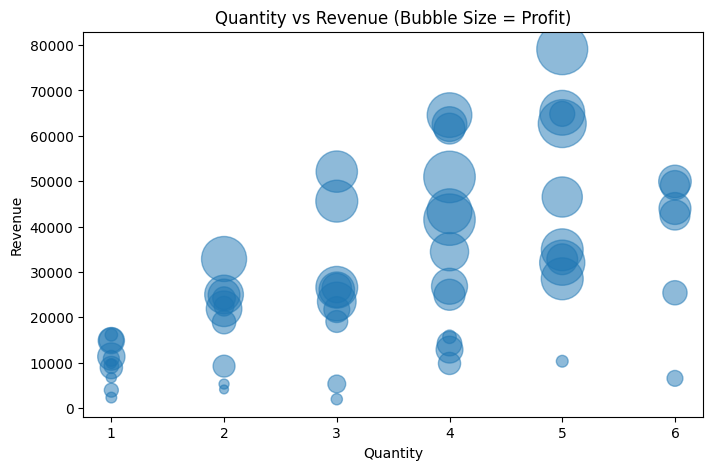

In [37]:
plt.figure(figsize=(8, 5))
plt.scatter(
    df["Quantity"],
    df["Revenue_INR"],
    s=df["Profit_INR"] / 10,
    alpha=0.5)

plt.xlabel("Quantity")
plt.ylabel("Revenue")
plt.title("Quantity vs Revenue (Bubble Size = Profit)")
plt.show()

In [38]:
pd.pivot_table(
    df,
    values="Revenue_INR",
    index="City",
    columns="Category",
    aggfunc="sum",
    fill_value=0
)

Category,Clothing,Electronics,Furniture,Grocery
City,,,,
Bengaluru,64463.35,14852.05,11330.40,118301.60
Chennai,137649.30,261906.30,99132.15,26601.90
Hyderabad,32785.00,103090.60,200529.60,43272.75
Kurnool,96241.00,283936.20,144618.20,44692.10


In [39]:
pd.pivot_table(
    df,
    values="Profit_INR",
    index="City",
    columns="Marketing_Channel",
    aggfunc="mean",
    fill_value=0
)

Marketing_Channel,Online,Social Media,Store
City,,,
Bengaluru,4325.110000,4327.580000,3886.8825
Chennai,2752.150000,2752.860000,5256.3230
Hyderabad,5686.793333,6271.566667,4348.2300
Kurnool,3297.682857,9230.606000,7010.4875


In [40]:
df.groupby("Category").agg(
    Total_Revenue=("Revenue_INR", "sum"),
    Average_Profit=("Profit_INR", "mean"),
    Average_Rating=("Customer_Rating", "mean"),
    Total_Quantity=("Quantity", "sum"))

,Total_Revenue,Average_Profit,Average_Rating,Total_Quantity
Category,,,,
Clothing,331138.65,3948.808571,3.742857,43
Electronics,663785.15,6482.326316,3.321053,67
Furniture,455610.35,5231.548235,3.494118,59
Grocery,232868.35,4162.191000,3.900000,30


In [41]:
df["Age_Group"] = pd.cut(
    df["Customer_Age"],
    bins=[17, 25, 35, 45, 60],
    labels=["18-25", "26-35", "36-45", "46-60"])
df.groupby("Age_Group", observed=False)["Revenue_INR"].mean()

Age_Group
18-25    27047.700000
26-35    26733.380952
36-45    27375.576471
46-60    30288.084211
Name: Revenue_INR, dtype: float64

In [42]:
df.groupby("Discount_Percent").agg(
    Average_Quantity=("Quantity", "mean"),
    Average_Revenue=("Revenue_INR", "mean"),
    Total_Profit=("Profit_INR", "sum"))

,Average_Quantity,Average_Revenue,Total_Profit
Discount_Percent,,,
0,3.000000,30122.125000,43654.29
5,3.538462,29816.553846,78017.29
10,3.222222,33953.700000,49900.20
15,3.636364,33038.959091,60966.64
20,3.000000,18291.200000,44949.81
25,3.375000,23074.406250,31517.52


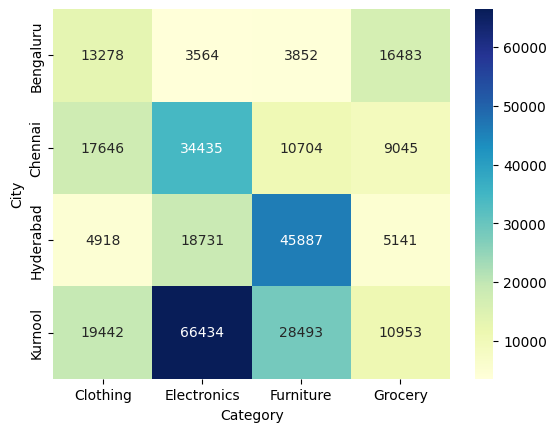

In [43]:
profit_table = df.pivot_table(
    values="Profit_INR",
    index="City",
    columns="Category",
    aggfunc="sum")
sns.heatmap(profit_table, annot=True, fmt=".0f", cmap="YlGnBu")
plt.show()

In [44]:
df.nlargest(5, "Profit_INR")[
    ["Order_ID", "Category", "Revenue_INR", "Profit_INR"]]

,Order_ID,Category,Revenue_INR,Profit_INR
28,ORD029,Furniture,50928.6,13750.72
35,ORD036,Furniture,41511.2,13698.70
6,ORD007,Electronics,79074.0,13442.58
53,ORD054,Electronics,62676.0,11908.44
30,ORD031,Electronics,32024.0,10567.92


In [45]:
df.groupby(["City", "Marketing_Channel"]).agg(
    Total_Revenue=("Revenue_INR", "sum"),
    Total_Profit=("Profit_INR", "sum"),
    Average_Rating=("Customer_Rating", "mean"),
    Total_Orders=("Order_ID", "count")).sort_values("Total_Revenue", ascending=False)

Total_Revenue  Total_Profit  Average_Rating  \
City      Marketing_Channel                                                
Chennai   Store                  350314.20      52563.23        3.660000   
Kurnool   Store                  257692.10      56083.90        3.500000   
          Social Media           208457.70      46153.03        2.900000   
Hyderabad Online                 169934.35      34120.76        3.883333   
          Store                  130833.65      21741.15        2.980000   
Chennai   Social Media           116237.20       8258.58        3.166667   
Kurnool   Online                 103337.70      23083.78        4.028571   
Hyderabad Social Media            78909.95      18814.70        3.866667   
Bengaluru Social Media            74432.00       8655.16        3.600000   
          Online                  68426.95      12975.33        3.233333   
          Store                   66088.45      15547.53        4.325000   
Chennai   Online                  58738.25      11008.60        3.275000   

                             Total_Orders  
City      Marketing_Channel                
Chennai   Store                        10  
Kurnool   Store                         8  
          Social Media                  5  
Hyderabad Online                        6  
          Store                         5  
Chennai   Social Media                  3  
Kurnool   Online                        7  
Hyderabad Social Media                  3  
Bengaluru Social Media                  2  
          Online                        3  
          Store                         4  
Chennai   Online                        4